# Project 13: CNN Architecture Comparison

## Introduction

- Different CNN architectures vary in depth, number of layers, and how they are connected
- A **Simple CNN** has fewer layers and fewer parameters — faster to train but may miss complex patterns
- **VGG-style CNN** uses multiple stacked convolutional layers before pooling — learns richer features but is heavier
- In this project, both architectures are built and trained on the **MNIST dataset** and their performance is compared
- Comparison is done based on: accuracy, number of parameters, confusion matrix, and classification report

## Task 1: Select and Implement Two CNN Models

**Model 1 — Simple CNN**
- 1 convolutional layer (32 filters)
- 1 max pooling layer
- 1 dense layer
- Fewer parameters, faster training

**Model 2 — VGG-style CNN**
- 2 blocks of stacked Conv layers (like VGG architecture)
- Each block has 2 Conv layers followed by Max Pooling
- More parameters, learns deeper features

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [2]:
# Load and preprocess MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
X_test  = X_test.reshape(-1, 28, 28, 1).astype('float32')  / 255.0

y_train_enc = to_categorical(y_train, 10)
y_test_enc  = to_categorical(y_test,  10)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (60000, 28, 28, 1)
Test shape : (10000, 28, 28, 1)


In [3]:
# ── Model 1: Simple CNN ──────────────────────────────────────
simple_cnn = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
], name='Simple_CNN')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
# ── Model 2: VGG-style CNN ───────────────────────────────────
vgg_cnn = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
], name='VGG_Style_CNN')

simple_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
vgg_cnn.compile(optimizer='adam',    loss='categorical_crossentropy', metrics=['accuracy'])

print("\n── Simple CNN Summary ──")
simple_cnn.summary()

print("\n── VGG-Style CNN Summary ──")
vgg_cnn.summary()


── Simple CNN Summary ──


Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

...

Model: "VGG_Style_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 467,818 (1.78 MB)

 Trainable params: 467,818 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

## Task 2: Train Both Models on the Same Dataset

- Both models are trained on the same MNIST training data
- Same number of epochs (5), same batch size (64)
- Same train/test split is used for a fair comparison

In [5]:
print("Training Simple CNN...")
history_simple = simple_cnn.fit(X_train, y_train_enc,
                                 epochs=5, batch_size=64,
                                 validation_split=0.1,
                                 verbose=1)

print("\nTraining VGG-Style CNN...")
history_vgg = vgg_cnn.fit(X_train, y_train_enc,
                            epochs=5, batch_size=64,
                            validation_split=0.1,
                            verbose=1)

Training Simple CNN...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 27s 31ms/step - accuracy: 0.9357 - loss: 0.2227 - val_accuracy: 0.9768 - val_loss: 0.0827
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 30ms/step - accuracy: 0.9781 - loss: 0.0722 - val_accuracy: 0.9790 - val_loss: 0.0680
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.9853 - loss: 0.0497 - val_accuracy: 0.9858 - val_loss: 0.0507
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.9890 - loss: 0.0357 - val_accuracy: 0.9857 - val_loss: 0.0563
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9914 - loss: 0.0275 - val_accuracy: 0.9878 - val_loss: 0.0487

Training VGG-Style CNN...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 194s 227ms/step - accuracy: 0.9561 - loss: 0.1405 - val_accuracy: 0.9860 - val_loss: 0.0510
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 202s 227ms/step - accuracy: 0.9882 - loss: 0.0389 - val_accuracy: 0.9902 - val_loss: 0.0380
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 209s

## Task 3: Compare Both Models

### 3.1 — Accuracy and Complexity Comparison

In [6]:
# Test accuracy
loss_s, acc_s = simple_cnn.evaluate(X_test, y_test_enc, verbose=0)
loss_v, acc_v = vgg_cnn.evaluate(X_test,   y_test_enc, verbose=0)

params_s = simple_cnn.count_params()
params_v = vgg_cnn.count_params()

print(f"{'Metric':<25} {'Simple CNN':>15} {'VGG-Style CNN':>15}")
print("-" * 57)
print(f"{'Test Accuracy':<25} {round(acc_s*100,2):>14}% {round(acc_v*100,2):>14}%")
print(f"{'Test Loss':<25} {round(loss_s,4):>15} {round(loss_v,4):>15}")
print(f"{'Total Parameters':<25} {params_s:>15,} {params_v:>15,}")

Metric                         Simple CNN   VGG-Style CNN
---------------------------------------------------------
Test Accuracy                      98.51%          98.97%
Test Loss                          0.0474          0.0281
Total Parameters                  347,146         467,818


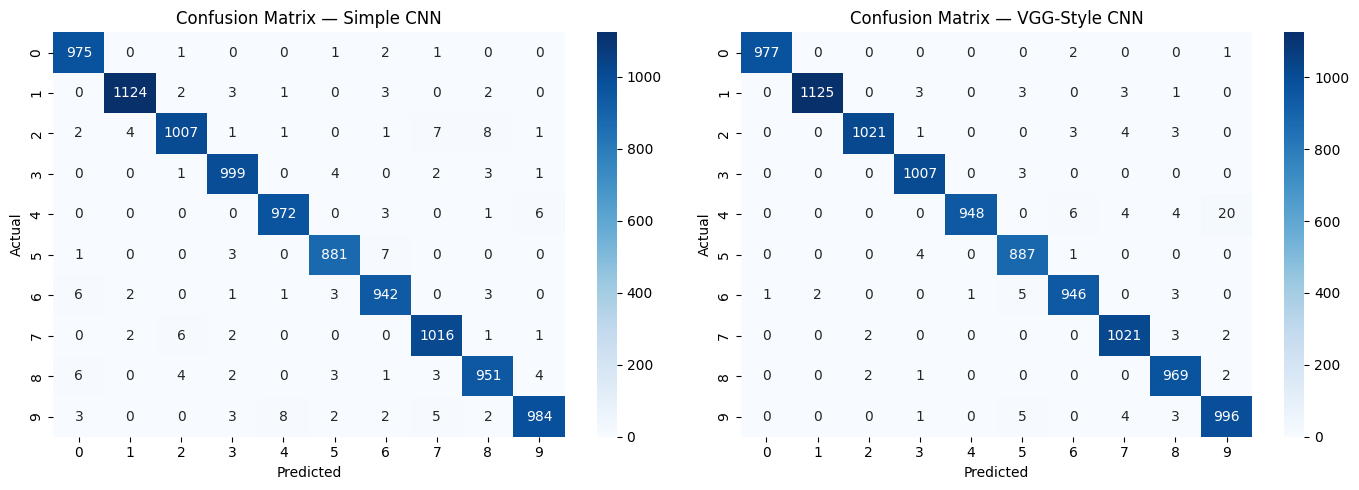

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_pred_s = np.argmax(simple_cnn.predict(X_test, verbose=0), axis=1)
y_pred_v = np.argmax(vgg_cnn.predict(X_test,    verbose=0), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title in zip(axes,
                               [y_pred_s, y_pred_v],
                               ['Simple CNN', 'VGG-Style CNN']):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(10), yticklabels=range(10), ax=ax)
    ax.set_title(f'Confusion Matrix — {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [8]:
digit_names = [str(i) for i in range(10)]

print("── Classification Report: Simple CNN ──\n")
print(classification_report(y_test, y_pred_s, target_names=digit_names))

print("── Classification Report: VGG-Style CNN ──\n")
print(classification_report(y_test, y_pred_v, target_names=digit_names))

── Classification Report: Simple CNN ──

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.99      0.98      0.98      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.98      0.98      0.98       958
           7       0.98      0.99      0.99      1028
           8       0.98      0.98      0.98       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.98      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

── Classification Report: VGG-Style CNN ──

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       980
           1       1.00      0.99      0.99    

## Conclusion

- Two CNN architectures were built and trained on the MNIST dataset for 5 epochs
- **Simple CNN** (1 Conv layer) has fewer parameters, trains faster, and still achieves good accuracy for a relatively easy dataset like MNIST
- **VGG-Style CNN** (4 Conv layers in 2 blocks) has more parameters and learns more detailed features — it may show slightly higher accuracy but takes longer to train
- The confusion matrix for both models shows that most digits are classified correctly; digits like 4/9 and 3/5 are the most common misclassifications
- The classification report confirms that precision, recall, and F1-score are consistently high across all digit classes for both models
- For simple datasets, a simple CNN is often good enough — deeper architectures like VGG show more benefit on complex datasets like CIFAR-10 or ImageNet where images have more detail and variation